# Diversity capstone: six buildings and matched retrofits

Run twelve small annual cases using current APIs, retain failures and aggregate only matched accepted pairs.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** local EPW, EnergyPlus 24.2.

## Understanding the API in this lesson

The capstone repeats the core unit of work across six explicit buildings and one insulation retrofit per building. Twelve annual cases demonstrate variation in form, height, climate and wall insulation. They are independent examples, not a geographically connected district.

The workflow figure describes the repeated unit: input, inspect, complete, compile/run and compare. The documentation sensitivity chart shows why retained assumptions and matched comparisons matter across climates. Its published example values are a separate reference study, not the expected numerical output of this capstone.

Reference: [From observed geometry to an accepted energy comparison](../../docs/figures/workflow.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Construct six physical cases

This pilot spans form, height, climate and wall insulation. The same wall-insulation measure is applied to each baseline; equal demonstration weights do not imply national population frequencies.

### Read the code and output

Keep each baseline and retrofit paired by building index. Only the added insulation should differ within a pair; the cross-building inputs deliberately vary. The six-case gallery is a diversity check, not proof that the chosen cases reproduce the country's joint distribution of size, age, use and location.

Reference: [Retained example: context sensitivity across three climates](../../docs/figures/context-sensitivity.svg). This linked documentation illustration is separate from the outputs computed below.

,case,area_m2,wall_U_W_m2K,weather
0,0-baseline,300.0,0.650344,SWE_VG_Gothenburg-Landvetter.AP.025260_TMYx.20...
1,0-retrofit,300.0,0.247669,SWE_VG_Gothenburg-Landvetter.AP.025260_TMYx.20...
2,1-baseline,1350.0,0.462396,SWE_SN_Malmo.AP-Sturup.026360_TMYx.2004-2018.epw
3,1-retrofit,1350.0,0.214470,SWE_SN_Malmo.AP-Sturup.026360_TMYx.2004-2018.epw
4,2-baseline,1860.0,0.358725,SWE_NB_Kiruna.AP.020440_TMYx.2004-2018.epw
5,2-retrofit,1860.0,0.189120,SWE_NB_Kiruna.AP.020440_TMYx.2004-2018.epw
6,3-baseline,1200.0,0.293028,SWE_VG_Gothenburg-Landvetter.AP.025260_TMYx.20...
7,3-retrofit,1200.0,0.169129,SWE_VG_Gothenburg-Landvetter.AP.025260_TMYx.20...
8,4-baseline,675.0,0.247669,SWE_SN_Malmo.AP-Sturup.026360_TMYx.2004-2018.epw
9,4-retrofit,675.0,0.152960,SWE_SN_Malmo.AP-Sturup.026360_TMYx.2004-2018.epw


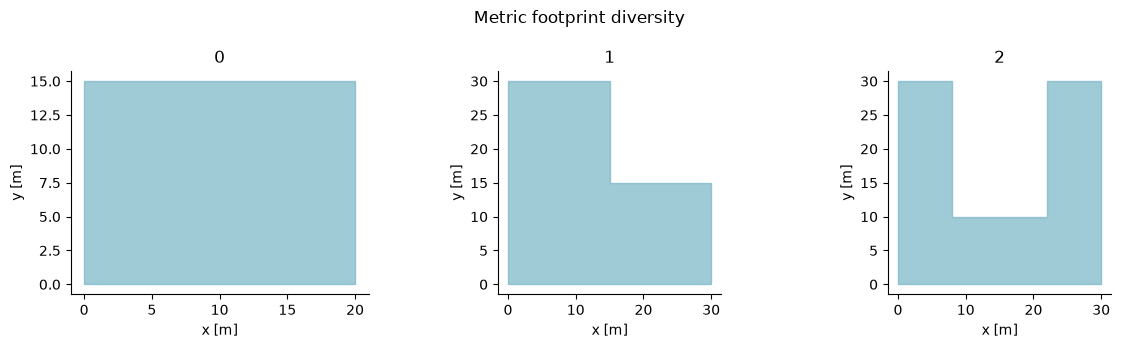

In [2]:
from concurrent.futures import ThreadPoolExecutor
forms=[Footprint.rectangle(20,15),Footprint.l_shape(30,30,15,15),Footprint.u_shape(30,30,14,20)]
cases=[]
for i in range(6):
    b=building(["Gothenburg","Malmo","Kiruna"][i%3],f"sample-{i}")
    wall=b.envelope.wall.updated(layers=(b.envelope.wall.layers[0].updated(thickness_m=.05+.025*i),*b.envelope.wall.layers[1:]))
    b=b.updated(geometry=geometry(forms[i%3],storeys=1+i%4),envelope=b.envelope.updated(wall=wall))
    retrofit=apply_renovation(b,AddInsulation(element="wall",layer=wall.layers[0].updated(thickness_m=.1)),effective_date="2026-01-01")
    cases.extend([(f"{i}-baseline",b),(f"{i}-retrofit",retrofit)])
table([{ "case":name,"area_m2":b.geometry.conditioned_floor_area_m2,"wall_U_W_m2K":b.envelope.wall.u_value_w_m2k,"weather":Path(b.climate.epw_path).name} for name,b in cases])
plans({str(i):form for i,form in enumerate(forms)})

## Run with explicit acceptance accounting

This notebook owns only a small experiment loop. Exceptions are recorded with their case identity; accepted pairs are required before calculating savings. This is not a retry or resume service.

### Read the code and output

The exception handler records failed cases rather than inventing successful results. The subsequent assertion stops the comparison if any pair is incomplete. This preserves the original denominator of twelve attempted cases and leaves the run manifest available for review. It is a small experiment loop, not a retry service.

,case,status,heating_kwh,run_id,area_m2
0,0-baseline,accepted,23573.221079,fbe280edff8db183e6d457086187fa7a69f53304e8c612...,300.0
1,0-retrofit,accepted,18098.258223,97f380410befdde9631a3b6a737110434c11dce4e22832...,300.0
2,1-baseline,accepted,60352.722514,14a4dbf6deb5f75d0fdf913495ba875b9166f486ceb21b...,1350.0
3,1-retrofit,accepted,50082.692102,703ecff26771c79701ff27ebc5883248de050d4f296774...,1350.0
4,2-baseline,accepted,193173.834307,9e90153cd4dbfd36968ccb66118afeac6d8a2e5748c5bb...,1860.0
5,2-retrofit,accepted,165481.164440,b95694c1a901677d0cf341d872d419c861ce1012dba991...,1860.0
6,3-baseline,accepted,54381.343646,570350e3be97b4060c363ca172dd8843914b777717d73a...,1200.0
7,3-retrofit,accepted,47608.871878,ccf6b9f5e33892bb609f9be5921c29aa9c1265b020fd8f...,1200.0
8,4-baseline,accepted,32596.956669,7161e1a715d533f0ba7cd1d74234abbc81e37220c863a0...,675.0
9,4-retrofit,accepted,30661.989927,3ebc217bef34ac7a295576086e28776c521b2ea6312cd7...,675.0


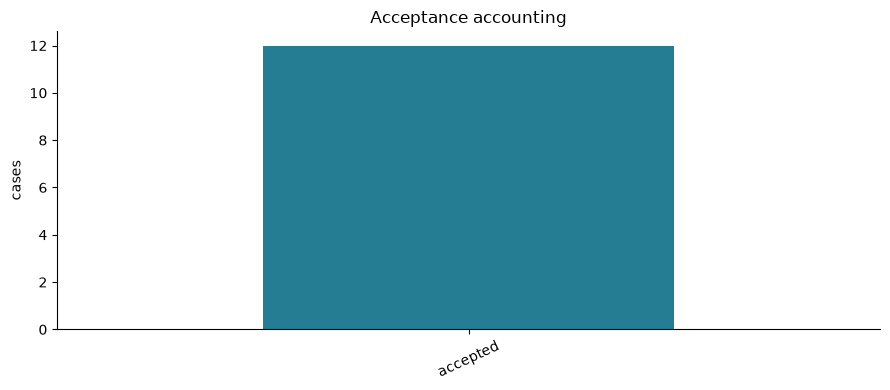

In [3]:
runner=EnergyPlusRunner(engine())
def run_case(item):
    name,spec=item
    try:
        result=runner.run(spec,OUT/name)
        return {"case":name,"status":"accepted","heating_kwh":result.scalars["space_heating_demand_kwh"],"run_id":result.run_id,"area_m2":spec.geometry.conditioned_floor_area_m2}
    except Exception as error:
        return {"case":name,"status":"failed","error":str(error)}
with ThreadPoolExecutor(max_workers=2) as pool:
    records=list(pool.map(run_case,cases))
(OUT/"manifest.json").write_text(json.dumps(records,indent=2))
frame=table(records)
bars(frame.status.value_counts().to_dict(),"cases","Acceptance accounting")
assert len(frame)==12 and (frame.status=="accepted").all(), "Inspect retained failures before comparing this pilot"

## Compare matched pairs

Only accepted baseline/retrofit pairs belong in the savings comparison. The result demonstrates heterogeneous response, not a national total.

### Read the code and output

Read absolute savings within each accepted pair. Comparing across buildings reveals heterogeneous response, but summing the six savings does not create a national estimate. Population weights, observed distributions and sampling uncertainty would need separate evidence before extrapolation.

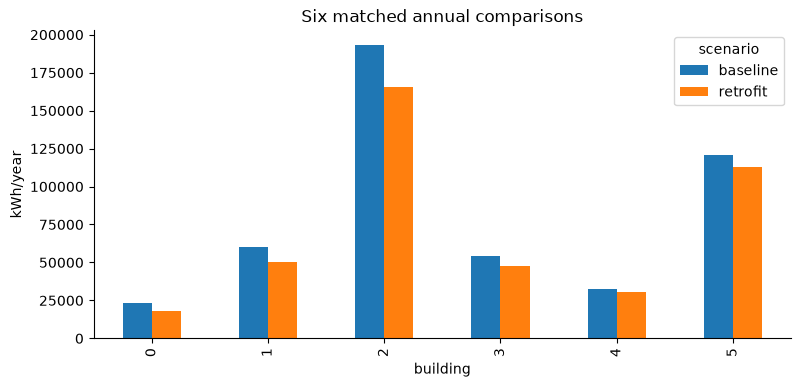

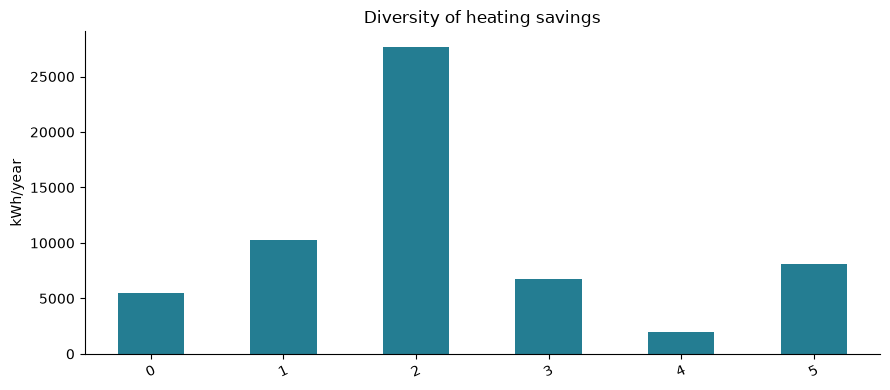

In [4]:
frame["building"]=frame.case.str.split('-').str[0]; frame["scenario"]=frame.case.str.split('-').str[1]
pairs=frame.pivot(index="building",columns="scenario",values="heating_kwh")
fig, ax = plt.subplots(figsize=(9, 4))
pairs.plot.bar(ax=ax, ylabel="kWh/year",title="Six matched annual comparisons"); plt.show(); plt.close(fig)
bars((pairs.baseline-pairs.retrofit).to_dict(),"kWh/year","Diversity of heating savings")
assert len(pairs)==6

## Interpretation and next experiment

A national application needs observed distributions, spatial input assignment and orchestration upstream. This capstone verifies the core unit of work across diverse inputs.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.